# Phase 3 — State Transitions (RQ2) & Prediction Dataset

**Proposal sections:** 3.4 (transition matrix) · 3.5 Historical-State Construction · 3.6 Leakage Control

**Input:** `data/processed/panel_with_states.parquet` (notebook 02)
**Outputs:**
- `data/processed/prediction_dataset.parquet` / `.csv` — one row per customer × origin t, current features, `Segment_t`, `Segment_t-1`, `Segment_t-2`, `StateDuration`, target `Segment_t+1`, split flags
- `outputs/tables/phase3_*.csv`, `outputs/figures/phase3_*.png`

**Part A (RQ2)** describes how customers move between the four states over the seven transitions S1→S2 … S7→S8.
**Part B** builds the supervised dataset for Phase 4. The history-dependent analyses that could inform H1 (Section 4) use **training origins only**, so the test origins S6–S7 stay untouched until final evaluation.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats

from config import (PROCESSED, FIGURES, TABLES, SNAPSHOT_ORDER, TRAIN_ORIGINS, TEST_ORIGINS, N_STATES,
                    STATE_NAMES, STATE_COLORS, CONFIG_A, CONFIG_B, TARGET, DURATION_CAP, TUNING_FOLDS)
from dataset import state_wide, build_dataset

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
pd.set_option("display.width", 180)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
                     "axes.edgecolor": "#9a9a92", "xtick.color": "#5c5c57", "ytick.color": "#5c5c57", "font.size": 10})
BLUES = LinearSegmentedColormap.from_list("blues", ["#f4f8fd", "#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#104281", "#0d366b"])
SHORT = {k: f"{k} {v}" for k, v in STATE_NAMES.items()}

panel = pd.read_parquet(PROCESSED / "panel_with_states.parquet")
wide = state_wide(panel)
print(f"{len(panel):,} customer-snapshot rows | {wide.shape[0]:,} customers | states: {N_STATES}")

33,842 customer-snapshot rows | 5,843 customers | states: 4


# Part A — Transition analysis (RQ2)
## A1. All observed transitions t → t+1

In [2]:
pairs = []
for a, b in zip(SNAPSHOT_ORDER[:-1], SNAPSHOT_ORDER[1:]):
    m = wide[a].notna() & wide[b].notna()
    pairs.append(pd.DataFrame({"CustomerID": wide.index[m], "from": wide.loc[m, a].astype(int).values,
                               "to": wide.loc[m, b].astype(int).values, "transition": f"{a}→{b}"}))
pairs = pd.concat(pairs, ignore_index=True)
counts = pd.crosstab(pairs["from"], pairs["to"]).reindex(index=range(N_STATES), columns=range(N_STATES), fill_value=0)
probs = counts.div(counts.sum(axis=1), axis=0)
counts.index = probs.index = [SHORT[i] for i in counts.index]
counts.columns = probs.columns = [SHORT[i] for i in counts.columns]
print(f"{len(pairs):,} observed transitions (pooled over S1→S2 … S7→S8)")
pd.concat({"count": counts, "P(to | from)": probs}, axis=1)

27,999 observed transitions (pooled over S1→S2 … S7→S8)


count                                                                       P(to | from)                                             \
                       0 Dormant Low-Value 1 Lapsing Mid-Value 2 Recent Low-Frequency 3 Active High-Value 0 Dormant Low-Value 1 Lapsing Mid-Value 2 Recent Low-Frequency   
0 Dormant Low-Value                   9214                1022                    940                  26               0.823               0.091                  0.084   
1 Lapsing Mid-Value                    371                6508                    392                1361               0.043               0.754                  0.045   
2 Recent Low-Frequency                1152                1707                    484                 351               0.312               0.462                  0.131   
3 Active High-Value                      0                 601                      0                3870               0.000               0.134                  0.000   

                                            
                       3 Active High-Value  
0 Dormant Low-Value                  0.002  
1 Lapsing Mid-Value                  0.158  
2 Recent Low-Frequency               0.095  
3 Active High-Value                  0.866

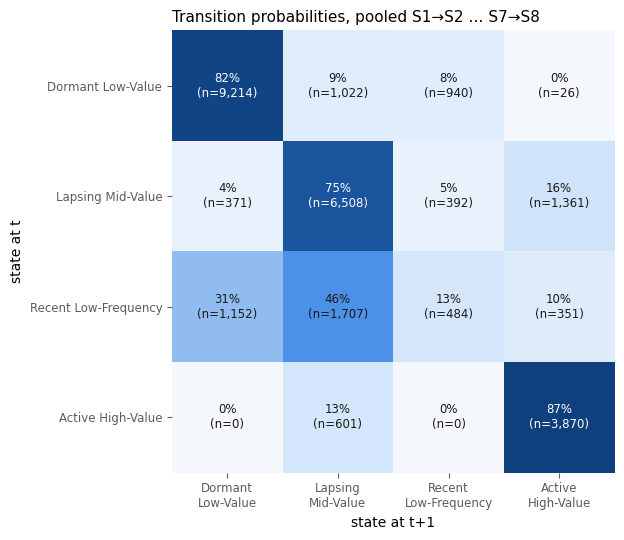

In [3]:
def heatmap(ax, P, N, title):
    ax.imshow(P.values, cmap=BLUES, vmin=0, vmax=1)
    for i in range(P.shape[0]):
        for j in range(P.shape[1]):
            v = P.values[i, j]
            ax.text(j, i, f"{v:.0%}\n(n={N.values[i, j]:,})", ha="center", va="center", fontsize=8.5,
                    color="white" if v > 0.5 else "#1a1a19")
    ax.set_xticks(range(N_STATES), [STATE_NAMES[i].replace(" ", "\n", 1) for i in range(N_STATES)], fontsize=8.5)
    ax.set_yticks(range(N_STATES), [STATE_NAMES[i] for i in range(N_STATES)], fontsize=8.5)
    ax.set_xlabel("state at t+1"); ax.set_ylabel("state at t"); ax.grid(False)
    ax.set_title(title, loc="left", fontsize=11)
    for s in ax.spines.values(): s.set_visible(False)

fig, ax = plt.subplots(figsize=(7.5, 5.5))
heatmap(ax, probs, counts, "Transition probabilities, pooled S1→S2 … S7→S8")
fig.tight_layout(); fig.savefig(FIGURES / "phase3_transition_matrix.png", dpi=150, bbox_inches="tight")

## A2. Persistence and the most frequent movements

In [4]:
persist = pd.DataFrame({
    "overall": pairs.groupby("transition", sort=False).apply(lambda g: (g["from"] == g["to"]).mean()),
    **{STATE_NAMES[s]: pairs[pairs["from"] == s].groupby("transition", sort=False).apply(lambda g: (g["to"] == s).mean())
       for s in range(N_STATES)}})
persist["n transitions"] = pairs.groupby("transition", sort=False).size()
persist

,overall,Dormant Low-Value,Lapsing Mid-Value,Recent Low-Frequency,Active High-Value,n transitions
transition,,,,,,
S1→S2,0.460,0.640,0.596,0.161,0.899,2132
S2→S3,0.603,0.756,0.626,0.151,0.886,2946
S3→S4,0.620,0.702,0.755,0.041,0.848,3530
S4→S5,0.786,0.897,0.781,0.078,0.839,4303
S5→S6,0.781,0.884,0.793,0.100,0.864,4680
S6→S7,0.792,0.891,0.768,0.162,0.860,5007
S7→S8,0.765,0.831,0.764,0.205,0.887,5401


In [5]:
moves = pairs[pairs["from"] != pairs["to"]].groupby(["from", "to"]).size().rename("count").reset_index()
moves["share of all movements"] = moves["count"] / moves["count"].sum()
moves["P(to | from)"] = probs.values[moves["from"].values, moves["to"].values]
moves["movement"] = moves["from"].map(STATE_NAMES) + "  →  " + moves["to"].map(STATE_NAMES)
moves = moves.sort_values("count", ascending=False)[["movement", "count", "share of all movements", "P(to | from)"]]
print(f"Share of transitions that change state: {(pairs['from'] != pairs['to']).mean():.1%}")
moves.reset_index(drop=True)

Share of transitions that change state: 28.3%


,movement,count,share of all movements,P(to | from)
0,Recent Low-Frequency → Lapsing Mid-Value,1707,0.215,0.462
1,Lapsing Mid-Value → Active High-Value,1361,0.172,0.158
2,Recent Low-Frequency → Dormant Low-Value,1152,0.145,0.312
3,Dormant Low-Value → Lapsing Mid-Value,1022,0.129,0.091
4,Dormant Low-Value → Recent Low-Frequency,940,0.119,0.084
5,Active High-Value → Lapsing Mid-Value,601,0.076,0.134
6,Lapsing Mid-Value → Recent Low-Frequency,392,0.049,0.045
7,Lapsing Mid-Value → Dormant Low-Value,371,0.047,0.043
8,Recent Low-Frequency → Active High-Value,351,0.044,0.095
9,Dormant Low-Value → Active High-Value,26,0.003,0.002


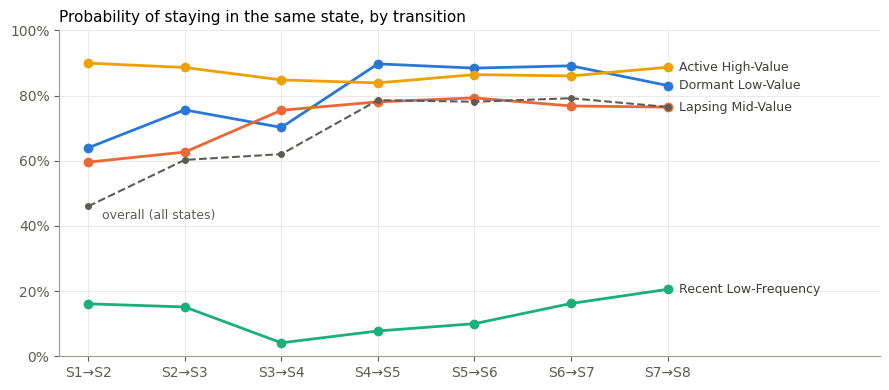

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(persist))
for s in range(N_STATES):
    y = persist[STATE_NAMES[s]].values
    ax.plot(x, y, color=STATE_COLORS[s], marker="o", markersize=6, linewidth=2)
    ax.annotate(STATE_NAMES[s], (x[-1], y[-1]), xytext=(8, 0), textcoords="offset points",
                va="center", fontsize=9, color="#3d3d3a")
ax.plot(x, persist["overall"].values, color="#5c5c57", linestyle="--", linewidth=1.5, marker="o", markersize=4)
ax.annotate("overall (all states)", (x[0], persist["overall"].values[0]), xytext=(10, -2), textcoords="offset points",
            va="top", fontsize=9, color="#5c5c57")
ax.set_xticks(x, persist.index); ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Probability of staying in the same state, by transition", loc="left", fontsize=11)
ax.set_xlim(-0.3, len(x) + 1.2)
fig.tight_layout(); fig.savefig(FIGURES / "phase3_persistence_by_transition.png", dpi=150, bbox_inches="tight")

## A3. Where do new customers enter?

In [7]:
first_snap = wide.notna().idxmax(axis=1)
entry_state = pd.Series([wide.at[c, s] for c, s in first_snap.items()], index=wide.index).astype(int)
entry = pd.crosstab(first_snap.rename("first snapshot"), entry_state).reindex(SNAPSHOT_ORDER).fillna(0).astype(int)
entry.columns = [SHORT[c] for c in entry.columns]
entry["new customers"] = entry.sum(axis=1)
entry

,0 Dormant Low-Value,1 Lapsing Mid-Value,2 Recent Low-Frequency,3 Active High-Value,new customers
first snapshot,,,,,
S1,813,319,851,149,2132
S2,405,62,345,2,814
S3,244,35,302,4,585
S4,480,116,167,10,773
S5,152,16,206,3,377
S6,150,22,149,6,327
S7,132,28,235,2,397
S8,170,22,235,11,438


From S2 onward, new customers enter almost only in two states: **Recent Low-Frequency** (first purchase in the last weeks of the quarter) and **Dormant Low-Value** (a single purchase earlier in the quarter, so Recency is already one to three months at the snapshot). Very few enter directly into *Lapsing Mid-Value* or *Active High-Value*. Recent Low-Frequency is fed both by newcomers and by re-activated dormant customers (Dormant → Recent, 940 transitions), and it is the least persistent state: most of its customers move on to *Lapsing Mid-Value* or fall back to *Dormant* one quarter later.

## A4. Are the transition probabilities stable over time?

For each origin state, a χ² test of homogeneity compares the distribution of next states across the seven transitions. A significant result means the transition matrix is **not time-homogeneous** — one reason to model next-state membership with classifiers rather than a single fixed Markov matrix.

In [8]:
homog = []
for s in range(N_STATES):
    tab = pd.crosstab(pairs.loc[pairs["from"] == s, "transition"], pairs.loc[pairs["from"] == s, "to"])
    tab = tab.loc[:, tab.sum() > 0]
    chi2, pval, dof, _ = stats.chi2_contingency(tab)
    n = tab.values.sum()
    homog.append({"from state": STATE_NAMES[s], "n": n, "chi2": chi2, "dof": dof, "p-value": pval,
                  "Cramér's V": np.sqrt(chi2 / (n * (min(tab.shape) - 1)))})
homogeneity = pd.DataFrame(homog)
homogeneity

,from state,n,chi2,dof,p-value,Cramér's V
0,Dormant Low-Value,11202,750.827,18,0.000,0.149
1,Lapsing Mid-Value,8632,219.628,18,0.000,0.092
2,Recent Low-Frequency,3694,145.787,18,0.000,0.115
3,Active High-Value,4471,12.816,6,0.046,0.054


**Result.** The next-state distribution changes significantly over time for every origin state (p < 0.05), most strongly for *Dormant Low-Value* (Cramér's V = 0.15); *Active High-Value* is almost stable (V = 0.05, p = 0.046). Much of the change sits in the first two transitions (S1→S2, S2→S3), when the panel still consists mainly of very new customers; from S4→S5 onward persistence is fairly flat at 77–79 %.

## A5. Structural zeros from cumulative RFM

Two cells of the matrix are (almost) empty by construction: an **Active High-Value** customer cannot move to *Dormant Low-Value* or *Recent Low-Frequency*, because cumulative Frequency and Monetary never decrease (only a later cancellation can lower them). Inactive high-value customers therefore drift into *Lapsing Mid-Value* through growing Recency. This is the mechanical-accumulation limitation noted in proposal Section 3.8 and should be stated when RQ2 is reported.

In [9]:
pd.DataFrame({"from": "Active High-Value", "to": ["Dormant Low-Value", "Recent Low-Frequency"],
              "count": [counts.iloc[3, 0], counts.iloc[3, 2]]})

,from,to,count
0,Active High-Value,Dormant Low-Value,0
1,Active High-Value,Recent Low-Frequency,0


# Part B — Prediction dataset (Section 3.5)

For each origin t = S1 … S7 and each customer present at t and t+1:

| Column | Definition | Config A | Config B |
|---|---|---|---|
| Recency … RecentSpend | current behavioural features at t (8 columns) | ✓ | ✓ |
| `Segment_t` | current state | ✓ | ✓ |
| `Segment_t-1`, `Segment_t-2` | states at the two previous snapshots | | ✓ |
| `StateDuration` | consecutive snapshots (incl. t) spent in `Segment_t`, capped at 5 | | ✓ |
| `Segment_t+1` | **target** | | |

**History-eligible** rows (customer already present at t−2) exist from origin S3 onwards. The main A/B comparison uses only these rows, for both configurations.

**Why cap StateDuration at 5?** Duration is counted back over the observed panel, so the longest possible value grows with the origin (3 at S3 … 7 at S7). Without a cap, the test origins would contain values never seen in training. 5 is the longest run observable at the last training origin S5.

In [10]:
ds = build_dataset(panel)
print(f"{len(ds):,} rows (customer × origin with a target)")
pd.crosstab(ds["origin"], ds["history_eligible"], margins=True)

27,999 rows (customer × origin with a target)


history_eligible,False,True,All
origin,,,
S1,2132,0,2132
S2,2946,0,2946
S3,1398,2132,3530
S4,1357,2946,4303
S5,1150,3530,4680
S6,704,4303,5007
S7,721,4680,5401
All,10408,17591,27999


## B1. Leakage and consistency checks (Section 3.6)

In [11]:
from config import SNAPSHOT_INDEX
e = ds[ds["history_eligible"]]

# 1. the target comes from the next snapshot only
assert (ds["target_snapshot"].map(SNAPSHOT_INDEX) == ds["origin"].map(SNAPSHOT_INDEX) + 1).all()
# 2. the target is never an input column
assert TARGET not in CONFIG_A and TARGET not in CONFIG_B
# 3. lags equal the states actually recorded at t-1 and t-2
for lag in (1, 2):
    prev = ds["origin"].map(lambda s: SNAPSHOT_ORDER[SNAPSHOT_ORDER.index(s) - lag] if SNAPSHOT_ORDER.index(s) >= lag else None)
    look = panel.set_index(["CustomerID", "snapshot"])["Segment"]
    ok = [pd.isna(v) if p is None or (c, p) not in look.index else v == look[(c, p)]
          for c, p, v in zip(ds["CustomerID"], prev, ds[f"Segment_t-{lag}"])]
    assert all(ok), f"lag {lag} mismatch"
# 4. duration is consistent with the lags (duration >= 3  <=>  t, t-1, t-2 all equal)
assert ((e["StateDuration_raw"] >= 3) == ((e["Segment_t"] == e["Segment_t-1"]) & (e["Segment_t-1"] == e["Segment_t-2"]))).all()
# 5. current features at t use only purchases up to t: inherited from notebook 01 (last_purchase <= snapshot date)
# 6. history-eligible rows have no missing inputs
assert e[CONFIG_B].notna().all().all()
print("All leakage / consistency checks passed ✓")

All leakage / consistency checks passed ✓


## B2. The main A/B dataset: history-eligible rows

In [12]:
main = ds[ds["history_eligible"] & ds["split"].isin(["train", "test"])].copy()
size = main.groupby(["split", "origin"]).size().rename("rows").to_frame()
size["target"] = main.groupby(["split", "origin"])["target_snapshot"].first()
size

rows target
split origin             
test  S6      4303     S7
      S7      4680     S8
train S3      2132     S4
      S4      2946     S5
      S5      3530     S6

In [13]:
cls = pd.crosstab(main["split"], main[TARGET], normalize="index")
cls.columns = [SHORT[c] for c in cls.columns]
cls_n = pd.crosstab(main["split"], main[TARGET]); cls_n.columns = cls.columns
pd.concat({"share": cls, "rows": cls_n}, axis=1)

share                                                                               rows                                                               
      0 Dormant Low-Value 1 Lapsing Mid-Value 2 Recent Low-Frequency 3 Active High-Value 0 Dormant Low-Value 1 Lapsing Mid-Value 2 Recent Low-Frequency 3 Active High-Value
split                                                                                                                                                                      
test                0.352               0.352                  0.043               0.253                3160                3163                    387                2273
train               0.301               0.412                  0.036               0.252                2590                3544                    308                2166

**Class imbalance.** In the history-eligible data the *Recent Low-Frequency* target is rare (≈ 4 %): customers with two snapshots of history are by definition not new, and this state is mainly an entry state (A3). Because Macro-F1 weights all four states equally, performance on this small class will weigh heavily on the primary metric. Phase 4 should therefore use class weighting and report per-class precision/recall alongside Macro-F1.

In [14]:
# How strong is the persistence benchmark on the training rows? (descriptive, training only)
print(f"Persistence rate, training origins S3–S5: {main.loc[main.split == 'train', 'persisted'].mean():.1%}")

Persistence rate, training origins S3–S5: 78.0%


## B3. Exploratory, training only: does history carry information beyond the current state?

A likelihood-ratio (G) test of conditional independence asks whether `Segment_t-1` is associated with `Segment_t+1` **within each value of `Segment_t`** — i.e. whether a first-order Markov chain is sufficient. This uses training origins only (S3–S5), so it does not touch the test data used for H1. It only tests the *states*; H1 itself (Phase 4/5) also controls for the current behavioural features, so this result motivates but does not answer H1.

In [15]:
tr = main[main["split"] == "train"]
rows, G_total, dof_total = [], 0.0, 0
for s in range(N_STATES):
    tab = pd.crosstab(tr.loc[tr["Segment_t"] == s, "Segment_t-1"], tr.loc[tr["Segment_t"] == s, TARGET])
    tab = tab.loc[tab.sum(axis=1) > 0, tab.sum(axis=0) > 0]
    if min(tab.shape) < 2:
        continue
    g, p, dof, _ = stats.chi2_contingency(tab, lambda_="log-likelihood")
    rows.append({"Segment_t": STATE_NAMES[s], "n": int(tab.values.sum()), "G": g, "dof": dof, "p-value": p})
    G_total += g; dof_total += dof
markov = pd.DataFrame(rows)
markov.loc[len(markov)] = {"Segment_t": "TOTAL (1st vs 2nd-order Markov)", "n": int(markov["n"].sum()),
                           "G": G_total, "dof": dof_total, "p-value": stats.chi2.sf(G_total, dof_total)}
markov

,Segment_t,n,G,dof,p-value
0,Dormant Low-Value,2827,39.514,6,0.000
1,Lapsing Mid-Value,3411,285.435,9,0.000
2,Recent Low-Frequency,462,101.879,6,0.000
3,Active High-Value,1908,242.588,3,0.000
4,TOTAL (1st vs 2nd-order Markov),8608,669.415,24,0.000


In [16]:
# What the dependence looks like: P(target | Segment_t, Segment_t-1), training rows
cond = (tr.groupby(["Segment_t", "Segment_t-1"])[TARGET].value_counts(normalize=True).unstack(fill_value=0))
cond["n"] = tr.groupby(["Segment_t", "Segment_t-1"]).size()
cond.columns = [SHORT.get(c, c) for c in cond.columns]
cond.index = cond.index.set_levels([[STATE_NAMES[i] for i in lev] for lev in cond.index.levels])
cond[cond["n"] >= 30]

0 Dormant Low-Value  1 Lapsing Mid-Value  2 Recent Low-Frequency  3 Active High-Value     n
Segment_t            Segment_t-1                                                                                                      
Dormant Low-Value    Dormant Low-Value                   0.860                0.081                   0.056                0.002  2555
                     Lapsing Mid-Value                   0.744                0.212                   0.045                0.000   156
                     Recent Low-Frequency                0.724                0.207                   0.069                0.000   116
Lapsing Mid-Value    Dormant Low-Value                   0.097                0.808                   0.069                0.026   390
                     Lapsing Mid-Value                   0.025                0.808                   0.035                0.132  2276
                     Recent Low-Frequency                0.052                0.768                   0.041                0.139   517
                     Active High-Value                   0.000                0.509                   0.000                0.491   228
Recent Low-Frequency Dormant Low-Value                   0.260                0.632                   0.074                0.035   258
                     Lapsing Mid-Value                   0.000                0.850                   0.007                0.143   147
                     Recent Low-Frequency                0.035                0.807                   0.035                0.123    57
Active High-Value    Lapsing Mid-Value                   0.000                0.338                   0.000                0.662   503
                     Recent Low-Frequency                0.000                0.278                   0.000                0.722    90
                     Active High-Value                   0.000                0.058                   0.000                0.942  1305

**Result (training origins only).** A first-order chain is clearly not sufficient for the states: G = 669 on 24 df, p < 0.001, significant within every current state. Examples from the table above:
- *Active High-Value* customers who were *Lapsing* one quarter earlier stay Active with 66 %, versus 94 % for those who were already Active.
- *Lapsing Mid-Value* customers who were *Active* one quarter earlier return to Active with 49 %, versus 13 % for those who were already Lapsing.
- *Recent Low-Frequency* customers coming from *Dormant* fall back to Dormant with 26 %, versus 0–4 % for the other histories.

This is evidence that past states carry information beyond `Segment_t` **at the state level**. Whether it remains useful once the current behavioural features (Recency, RecentOrders, …) are also in the model is exactly what H1 tests in Phase 4/5. Part of the dependence may already be captured by those features.

## B4. Save

In [17]:
keep = ["CustomerID", "origin", "t", "target_snapshot", "split", "history_eligible",
        *CONFIG_B, "StateDuration_raw", TARGET, "persisted"]
ds = ds[keep]
ds.to_parquet(PROCESSED / "prediction_dataset.parquet", index=False)
ds.to_csv(PROCESSED / "prediction_dataset.csv", index=False)

pd.concat({"count": counts, "P(to | from)": probs}, axis=1).to_csv(TABLES / "phase3_transition_matrix.csv")
persist.to_csv(TABLES / "phase3_persistence_by_transition.csv")
moves.to_csv(TABLES / "phase3_top_movements.csv", index=False)
entry.to_csv(TABLES / "phase3_entry_states.csv")
homogeneity.to_csv(TABLES / "phase3_time_homogeneity.csv", index=False)
markov.to_csv(TABLES / "phase3_markov_order_test_train.csv", index=False)
pd.concat({"share": cls, "rows": cls_n}, axis=1).to_csv(TABLES / "phase3_target_distribution.csv")
pd.DataFrame(TUNING_FOLDS).to_csv(TABLES / "phase3_tuning_folds.csv", index=False)
print(f"saved prediction_dataset: {len(ds):,} rows; main A/B rows: {len(main):,} "
      f"(train {int((main.split=='train').sum()):,} / test {int((main.split=='test').sum()):,})")

saved prediction_dataset: 27,999 rows; main A/B rows: 17,591 (train 8,608 / test 8,983)


## Summary & hand-off to Phase 4

**RQ2 (descriptive)** — see the cells above for the numbers quoted in the report: persistence, the most frequent movements, entry states, time-homogeneity, and the structural zeros caused by cumulative RFM.

**Prediction dataset** — `prediction_dataset.parquet`, main A/B rows = history-eligible, train origins S3–S5, test origins S6–S7.

**Phase 4 plan**
- Benchmarks: majority class, persistence (`Segment_t+1 = Segment_t`).
- Classifiers: Multinomial Logistic Regression, Random Forest, XGBoost × Config A / Config B, class-weighted.
- Tuning: expanding-window folds (S3 → S4, S3–S4 → S5). Inside each fold the states are re-fitted on that fold's past snapshots only and the dataset is rebuilt with `build_dataset`, so validation labels never shape the states.
- S6–S7 are used once, for the final evaluation.